# Week 7: Treatment effects — whose effect are we averaging?

**Central question:** we can never see the same customer with and without the discount. How do we fill in the missing outcome, and **whose** effect do we average?

| Part | Topic | Target |
|---|---|---|
| 1 | Scenario and data | — |
| 2 | Regression: predict each customer twice | ATE |
| 3 | Matching: borrow a comparable customer's outcome | ATE |
| 4 | Interaction: the effect depends on the customer | ATE, ATT, ATU, subgroups |
| 5 | Offer vs. use: the Wald estimate | LATE |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.linear_model import LinearRegression

BLUE, ORANGE, GREY = "#1B5AA6", "#D9822B", "#999999"


def draw_dag(edges, pos, title, figsize=(7, 3.6), red=()):
    """Draw one causal diagram. Nodes in `red` are unobserved."""
    fig, ax = plt.subplots(figsize=figsize)
    boxes = {}
    for node, (x, y) in pos.items():
        boxes[node] = ax.text(x, y, node, ha="center", va="center", fontsize=10,
                              bbox=dict(boxstyle="round,pad=0.4", ec="black", lw=1,
                                        fc="#FFE0E0" if node in red else "#D9EAF7"))
    for u, v in edges:  # arrows run box edge to box edge
        ax.annotate("", xy=pos[v], xytext=pos[u],
                    arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1.8, mutation_scale=18,
                                    patchA=boxes[u].get_bbox_patch(), patchB=boxes[v].get_bbox_patch(),
                                    shrinkA=2, shrinkB=2))
    xs, ys = zip(*pos.values())
    ax.set_xlim(min(xs) - 1, max(xs) + 1)
    ax.set_ylim(min(ys) - 0.5, max(ys) + 0.5)
    ax.set_title(title, fontsize=11)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

---
## Part 1: Scenario and data

A company gives some customers a discount. Does the discount raise **later engagement**?

- **Unit:** customer
- **Treatment:** `discount` (1 = received, 0 = not)
- **Outcome:** `later_engagement`
- **Confounder:** `initial_engagement` (P), measured **before** the discount
- More engaged customers are more likely to get the discount → a raw treated vs. untreated comparison is misleading

**The causal question:** how would later engagement differ if the **same** customers received the discount versus did not?

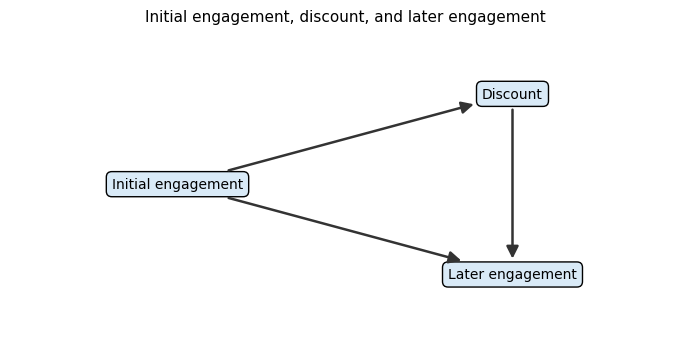

In [2]:
draw_dag([("Initial engagement", "Discount"),
          ("Initial engagement", "Later engagement"),
          ("Discount", "Later engagement")],
         {"Initial engagement": (0, 1), "Discount": (2, 1.7), "Later engagement": (2, 0.3)},
         "Initial engagement, discount, and later engagement")

### The simulation (Part 2)

- 20 customers
- Higher initial engagement → more likely to get the discount
- True rule: later engagement $= \text{discount} + P + \text{noise}$
- **True effect = 1** for every customer

In [3]:
np.random.seed(42)

n = 20

initial_engagement = np.random.normal(loc=0, scale=1, size=n)

logit = -0.2 + 1.2 * initial_engagement
prob_discount = 1 / (1 + np.exp(-logit))

discount = np.random.binomial(n=1, p=prob_discount, size=n)

noise = np.random.normal(loc=0, scale=0.5, size=n)

later_engagement = 1.0 * discount + initial_engagement + noise

data = pd.DataFrame({
    "initial_engagement": initial_engagement,
    "discount": discount,
    "later_engagement": later_engagement
})

data.head()

,initial_engagement,discount,later_engagement
0,0.496714,1,1.907987
1,-0.138264,1,0.251314
2,0.647689,1,1.752120
3,1.523030,1,1.543195
4,-0.234153,0,-0.898246


- Each customer has **one** observed outcome
- The other one (what would have happened under the other treatment) is missing
- Parts 2 and 3 are two ways to fill it in

---
## Part 2: Using regression to find counterfactuals

### Toy example

Four customers. Use this prediction equation (the coefficients are **given for this toy example**, not estimated from these rows):

$$\widehat{Y} = 0.25 + 1.5\,P + 2\,T$$

| customer | initial_engagement (P) | discount (T) | observed later_engagement |
|---|---|---|---|
| 0 | 0.5 | 1 | 2.0 |
| 1 | −0.2 | 1 | 0.8 |
| 2 | 1.1 | 0 | 1.4 |
| 3 | −0.7 | 0 | −0.3 |

For each customer: predict with T = 1, predict with T = 0, subtract.

```
Two approaches: model vs. model OR model vs. observed


```

In [25]:
# ATE, ATT, ATU

def y_pred(t,p):
    return 0.25 + 1.5*p + 2*t

ate = (y_pred(1, 0.5) - y_pred(0, 0.5) +\
y_pred(1, -0.2) - y_pred(0, -0.2) +\
y_pred(1, 1.1) - y_pred(0, 1.1) +\
y_pred(1, -0.7) - y_pred(0, -0.7))/4


# att
att = (y_pred(1, 0.5) - y_pred(0, 0.5) +\
y_pred(1, -0.2) - y_pred(0, -0.2))/2

# atu
atu = (y_pred(1, 1.1) - y_pred(0, 1.1) +\
y_pred(1, -0.7) - y_pred(0, -0.7))/2

print(ate)
print(att)
print(atu)

2.0
2.0
2.0


<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
✏️ <b style="color:#D9822B;">WORKED BY HAND</b> &nbsp;—&nbsp; regression toy: ATE, ATT, ATU
</div>

### Now the 20 simulated customers

Same steps, but the coefficients are **estimated** from the data.

In [26]:
X_model = data[["discount", "initial_engagement"]]
y_model = data["later_engagement"]

model = LinearRegression()
model.fit(X_model, y_model)

data_if_discount_1 = data.copy()
data_if_discount_1["discount"] = 1
data_if_discount_1["predicted_later_engagement"] = model.predict(
    data_if_discount_1[["discount", "initial_engagement"]]
)

data_if_discount_0 = data.copy()
data_if_discount_0["discount"] = 0
data_if_discount_0["predicted_later_engagement"] = model.predict(
    data_if_discount_0[["discount", "initial_engagement"]]
)

ate = (
    data_if_discount_1["predicted_later_engagement"].mean()
    - data_if_discount_0["predicted_later_engagement"].mean()
)

print(f"fitted discount coefficient:      {model.coef_[0]:.3f}")
print(f"average predicted difference:     {ate:.3f}")
print(f"true effect (simulation):         1")

fitted discount coefficient:      1.073
average predicted difference:     1.073
true effect (simulation):         1


<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
✏️ <b style="color:#D9822B;">LIVE CODE</b> &nbsp;—&nbsp; model + observed: build <code>data["y1"]</code> and <code>data["y0"]</code>
</div>

In [27]:
# ATE

data_copy = data.copy()

data_copy["y1"] = np.where(
    data_copy['discount'] == 1,
    data_copy['later_engagement'],
    data_if_discount_1["predicted_later_engagement"]
)

data_copy["y0"] = np.where(
    data_copy['discount'] == 0,
    data_copy['later_engagement'],
    data_if_discount_0["predicted_later_engagement"]
)

ate_mixed = (data_copy['y1'] - data_copy['y0']).mean()

print(f"average predicted difference:     {ate_mixed:.3f}")


average predicted difference:     1.073


**Takeaways**

- No interaction → every predicted difference equals the discount coefficient → ATE = coefficient
- The estimate isn't exactly 1: only 20 customers
- A predicted difference is a **model-based** estimate, not the customer's true individual effect
- **Assumption:** initial engagement is the only confounder, and the model's form is right

---
## Part 3: Matching — borrow a comparable customer's outcome

Instead of a model, use the **closest customer from the other group** as the missing outcome.

| customer | initial_engagement (P) | discount (T) | observed later_engagement |
|---|---|---|---|
| 0 | 0.50 | 1 | 2.0 |
| 1 | 0.60 | 1 | 2.2 |
| 2 | 0.55 | 0 | 1.1 |
| 3 | −0.70 | 0 | −0.3 |

Keep the direction of subtraction: **treated − untreated**.

In [29]:
# ATE

# c0 -> c2
# c1 -> c2
# c2 -> c0 or c1 or average of both
# c3 -> c0

ate = (2.0 - 1.1 + \
2.2 - 1.1 + \
(2.0+2.2)/2 - 1.1 + \
2.0 - (-0.3))/4

ate


1.325

<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
✏️ <b style="color:#D9822B;">WORKED BY HAND</b> &nbsp;—&nbsp; matching, customers 0 → 3 (tie: random vs. averaged)
</div>

---
## Part 4: Interaction — the effect depends on the customer

Back to Part 2's four customers. The equation now has an interaction term:

$$\widehat{Y} = 0.25 + 1.5\,P + 2\,T + 0.75\,T \times P$$

| customer | P | T | T × P | observed |
|---|---|---|---|---|
| 0 | 0.5 | 1 | 0.5 | 2.0 |
| 1 | −0.2 | 1 | −0.2 | 0.8 |
| 2 | 1.1 | 0 | 0.0 | 1.4 |
| 3 | −0.7 | 0 | 0.0 | −0.3 |

<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
✏️ <b style="color:#D9822B;">WORKED BY HAND</b> &nbsp;—&nbsp; interaction toy: ATE = 2 + 0.75 × average P
</div>

In [32]:
# ate
def y_pred(t,p):
    return 0.25 + 1.5*p + 2*t + 0.75*t*p


ate_1 = (y_pred(1,0.5) - y_pred(0,0.5) + \
       y_pred(1,-0.2) - y_pred(0,-0.2) + \
       y_pred(1,1.1) - y_pred(0,1.1) + \
       y_pred(1,-0.7) - y_pred(0,-0.7))/4



# ate = coeff of the treatemnt + coeff of interaction term * average P

p_avg = (0.5 -0.2 + 1.1 -0.7)/4

ate_2 = 2 + (0.75*p_avg)


print(ate_1)
print(ate_2)



2.1312499999999996
2.13125


### Now the simulation, with an interaction

- Same 20 customers, same discounts, same noise
- New true rule: later engagement $= \text{discount} + P + \text{discount} \times P + \text{noise}$
- True effect for a customer $= 1 + P$ → differs across customers

In [33]:
data_int = data[["initial_engagement", "discount"]].copy()
data_int["discount_initial_engagement"] = data_int["discount"] * data_int["initial_engagement"]
data_int["later_engagement"] = (
    data_int["discount"]
    + data_int["initial_engagement"]
    + data_int["discount_initial_engagement"]
    + noise
)

features = ["discount", "initial_engagement", "discount_initial_engagement"]

model_int = LinearRegression()
model_int.fit(data_int[features], data_int["later_engagement"])

data_int_if_discount_1 = data_int.copy()
data_int_if_discount_1["discount"] = 1
data_int_if_discount_1["discount_initial_engagement"] = data_int_if_discount_1["initial_engagement"]

data_int_if_discount_0 = data_int.copy()
data_int_if_discount_0["discount"] = 0
data_int_if_discount_0["discount_initial_engagement"] = 0

# two predictions per customer, kept for Part 5
data_int["predicted_if_1"] = model_int.predict(data_int_if_discount_1[features])
data_int["predicted_if_0"] = model_int.predict(data_int_if_discount_0[features])
data_int["predicted_difference"] = data_int["predicted_if_1"] - data_int["predicted_if_0"]

ate_int = data_int["predicted_difference"].mean()

print(f"fitted discount coefficient (effect at P = 0):  {model_int.coef_[0]:.3f}")
print(f"average predicted difference (ATE):             {ate_int:.3f}")
print(f"mean P in this sample:                          {data_int['initial_engagement'].mean():.3f}")
print(f"true ATE = 1 + mean P:                          {1 + data_int['initial_engagement'].mean():.3f}")

fitted discount coefficient (effect at P = 0):  1.176
average predicted difference (ATE):             0.954
mean P in this sample:                          -0.171
true ATE = 1 + mean P:                          0.829


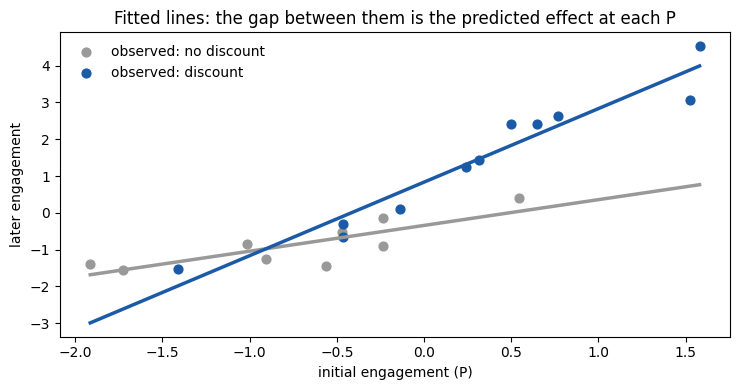

In [34]:
P_grid = np.linspace(data_int["initial_engagement"].min(), data_int["initial_engagement"].max(), 50)
b0 = model_int.intercept_
bT, bP, bTP = model_int.coef_

fig, ax = plt.subplots(figsize=(7.5, 4))
for t, color, label in [(0, GREY, "no discount"), (1, BLUE, "discount")]:
    rows = data_int["discount"] == t
    ax.scatter(data_int.loc[rows, "initial_engagement"], data_int.loc[rows, "later_engagement"],
               color=color, s=40, label=f"observed: {label}")
    ax.plot(P_grid, b0 + bP * P_grid + t * (bT + bTP * P_grid), color=color, lw=2.5)
ax.set_xlabel("initial engagement (P)")
ax.set_ylabel("later engagement")
ax.set_title("Fitted lines: the gap between them is the predicted effect at each P")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Takeaways**

- With an interaction, the predicted difference changes with P → there is no single "the effect"
- The discount coefficient is the effect at **P = 0** only
- The ATE averages the differences over **this sample's** P values
- They agree only if the sample's mean P is 0. Here mean P is below 0, so the ATE is below the coefficient.

### ATT and ATU: same predictions, different groups

Keep the same model and the same two predictions per customer. Only change **which rows we average**.

| Target | Average the predicted differences over |
|---|---|
| ATE | all customers |
| ATT | customers who **actually received** the discount |
| ATU | customers who **actually did not** receive it |
| Subgroup | customers with P > 0, or with P < 0 |

Toy example from above: each customer's predicted difference is $2 + 0.75\,P$.

### Discussion

1. Which customers belong in the ATT? In the ATU?
2. To predict "without discount" for customer 0, we set T = 0. Does customer 0 move to the ATU group?
3. Which is bigger, ATT or ATU? Look at each group's average P.

### Now the simulation

- Reuse `predicted_difference` from the interaction model above. No new model.
- True group average effect $= 1 + \text{group's mean } P$

In [35]:
groups = {
    "ATE (all)": data_int["discount"] >= 0,
    "ATT (received)": data_int["discount"] == 1,       # observed discount, not the switched one
    "ATU (did not receive)": data_int["discount"] == 0,
    "P > 0": data_int["initial_engagement"] > 0,
    "P < 0": data_int["initial_engagement"] < 0,
}

results = pd.DataFrame([
    {
        "group": name,
        "n": rows.sum(),
        "mean P": data_int.loc[rows, "initial_engagement"].mean(),
        "estimated effect": data_int.loc[rows, "predicted_difference"].mean(),
        "true average effect": 1 + data_int.loc[rows, "initial_engagement"].mean(),
    }
    for name, rows in groups.items()
])
results.round(2)

,group,n,mean P,estimated effect,true average effect
0,ATE (all),20,-0.17,0.95,0.83
1,ATT (received),11,0.28,1.54,1.28
2,ATU (did not receive),9,-0.72,0.24,0.28
3,P > 0,8,0.76,2.17,1.76
4,P < 0,12,-0.79,0.14,0.21


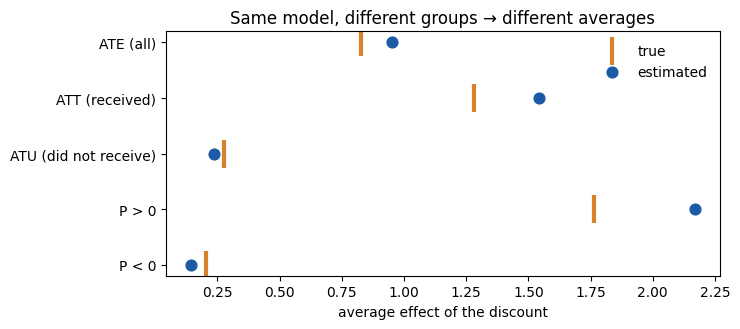

In [36]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(results))
ax.scatter(results["true average effect"], y, marker="|", s=400, color=ORANGE, lw=3, label="true")
ax.scatter(results["estimated effect"], y, s=60, color=BLUE, label="estimated", zorder=3)
ax.set_yticks(y, results["group"])
ax.invert_yaxis()
ax.set_xlabel("average effect of the discount")
ax.set_title("Same model, different groups → different averages")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

In [37]:
n_T = (data_int["discount"] == 1).sum()
n_U = (data_int["discount"] == 0).sum()
att_sim = results.loc[1, "estimated effect"]
atu_sim = results.loc[2, "estimated effect"]

print(f"ATE                          = {ate_int:.3f}")
print(f"{n_T}/{n} × ATT + {n_U}/{n} × ATU     = {n_T / n * att_sim + n_U / n * atu_sim:.3f}")

ATE                          = 0.954
11/20 × ATT + 9/20 × ATU     = 0.954


**Takeaways**

- ATE, ATT, ATU: **same** per-customer differences, different rows averaged
- Groups with higher average P have bigger effects here, because the true effect is 1 + P
- ATE is the size-weighted average of ATT and ATU
- The P > 0 and P < 0 rows are **subgroup averages**: not one customer's effect, and not the CATE at one exact P
- The CATE at an exact value p is the gap between the two fitted lines at p: $\hat\beta_T + \hat\beta_{TP}\,p$

---
## Part 5: Offer vs. use — the Wald estimate computes LATE

A **different study**:

- The discount **offer** is randomized (`discount_offer`)
- Customers choose whether to **use** it (`discount_used`)
- Unobserved **motivation** affects both use and later engagement
- Comparing users with non-users is confounded by motivation, and we can't control for it

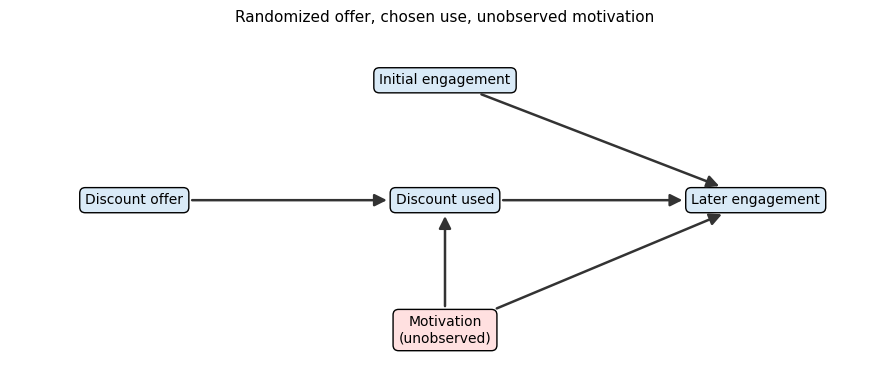

In [38]:
draw_dag([("Discount offer", "Discount used"),
          ("Discount used", "Later engagement"),
          ("Initial engagement", "Later engagement"),
          ("Motivation\n(unobserved)", "Discount used"),
          ("Motivation\n(unobserved)", "Later engagement")],
         {"Initial engagement": (2.5, 1.6), "Motivation\n(unobserved)": (2.5, -0.9),
          "Discount offer": (0, 0.4), "Discount used": (2.5, 0.4), "Later engagement": (5, 0.4)},
         "Randomized offer, chosen use, unobserved motivation", figsize=(9, 4),
         red={"Motivation\n(unobserved)"})

### Puzzle

Eight customers. **Group by the offer, not by use.**

| customer | discount_offer | discount_used | later_engagement |
|---|---|---|---|
| 0 | 1 | 1 | 5.0 |
| 1 | 1 | 1 | 3.0 |
| 2 | 1 | 0 | 2.0 |
| 3 | 1 | 1 | 4.0 |
| 4 | 0 | 1 | 4.0 |
| 5 | 0 | 0 | 1.0 |
| 6 | 0 | 0 | 2.0 |
| 7 | 0 | 0 | 1.0 |

```
ITT (offer → engagement):      (? + ? + ? + ?)/4 − (? + ? + ? + ?)/4 = ?
Share of compliers (offer → use):  (? + ? + ? + ?)/4 − (? + ? + ? + ?)/4 = ?

Wald = ITT / share of compliers = ?
```

### Discussion

1. Why not compare customers who used the discount with those who didn't?
2. Among those offered, how many used it? Among those not offered?
3. Customer 4 used it without an offer. What type is customer 4 likely to be?

<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
✏️ <b style="color:#D9822B;">WORKED BY HAND</b> &nbsp;—&nbsp; Wald: ITT ÷ share of compliers
</div>

In [41]:
ITT = (5.0 + 3.0 + 2.0 + 4.0)/4 - (4.0 + 1.0 + 2.0 + 1.0)/4
share_of_compliers = (1 + 1 + 0 + 1)/4 - (1 + 0 + 0 + 0)/4

wald = ITT/share_of_compliers

# this is Local Average Treatment Effect (LATE) because it is the average of the treatment effect local to compliers
print(wald)




3.0


**Takeaways**

- The Wald **estimator** (ITT ÷ share of compliers) computes the LATE **estimand**
- LATE is the effect for **compliers**: customers whose use changes because of the offer
- It is not the ATE. Always-takers and never-takers don't contribute (slides 8–9).